In [1]:
import os
import sys

sys.path.append(os.path.abspath(".."))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django
django.setup()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_engine.models import IndicadorEconomico

In [3]:
filas = (
    IndicadorEconomico.objects
    .filter(indicador="uf")
    .order_by("fecha")
    .values("fecha", "valor")
)
uf = pd.DataFrame.from_records(filas)
uf["fecha"] = pd.to_datetime(uf["fecha"])
uf["valor"] = uf["valor"].astype(float)
uf = uf.set_index("fecha")["valor"]

print(uf.head(3))
print(uf.tail(3))
print(len(uf))

fecha
1977-08-01    389.10
1977-08-02    389.51
1977-08-03    389.91
Name: valor, dtype: float64
fecha
2026-11-07    41284.83
2026-11-08    41290.15
2026-11-09    41295.46
Name: valor, dtype: float64
17996


In [4]:
uf_dia9 = uf[uf.index.day == 9]

# Variación mensual en %, fechada en el mes del IPC que representa (2 meses antes)
inflacion_mensual = uf_dia9.pct_change() * 100
inflacion_mensual.index = (inflacion_mensual.index - pd.DateOffset(months=2)).to_period("M")
inflacion_mensual = inflacion_mensual.dropna()

# Inflación acumulada en 12 meses, la que se reporta en las noticias
inflacion_12m = (uf_dia9 / uf_dia9.shift(12) - 1) * 100
inflacion_12m.index = (inflacion_12m.index - pd.DateOffset(months=2)).to_period("M")
inflacion_12m = inflacion_12m.dropna()

print(inflacion_mensual.tail(6).round(2))
print(inflacion_12m.tail(6).round(2))

fecha
2026-04    1.3
2026-05    0.2
2026-06    0.0
2026-07    0.1
2026-08    0.6
2026-09    0.4
Freq: M, Name: valor, dtype: float64
fecha
2026-04    3.96
2026-05    3.96
2026-06    4.37
2026-07    3.55
2026-08    4.17
2026-09    4.17
Freq: M, Name: valor, dtype: float64


In [5]:
filas = (
    IndicadorEconomico.objects
    .filter(indicador="uf")
    .order_by("fecha")
    .values("fecha", "valor")
)
uf = pd.DataFrame.from_records(filas)
uf["fecha"] = pd.to_datetime(uf["fecha"])
uf["valor"] = uf["valor"].astype(float)
uf = uf.set_index("fecha")["valor"]

print(uf.head(3))
print(uf.tail(3))
print(len(uf))

fecha
1977-08-01    389.10
1977-08-02    389.51
1977-08-03    389.91
Name: valor, dtype: float64
fecha
2026-11-07    41284.83
2026-11-08    41290.15
2026-11-09    41295.46
Name: valor, dtype: float64
17996


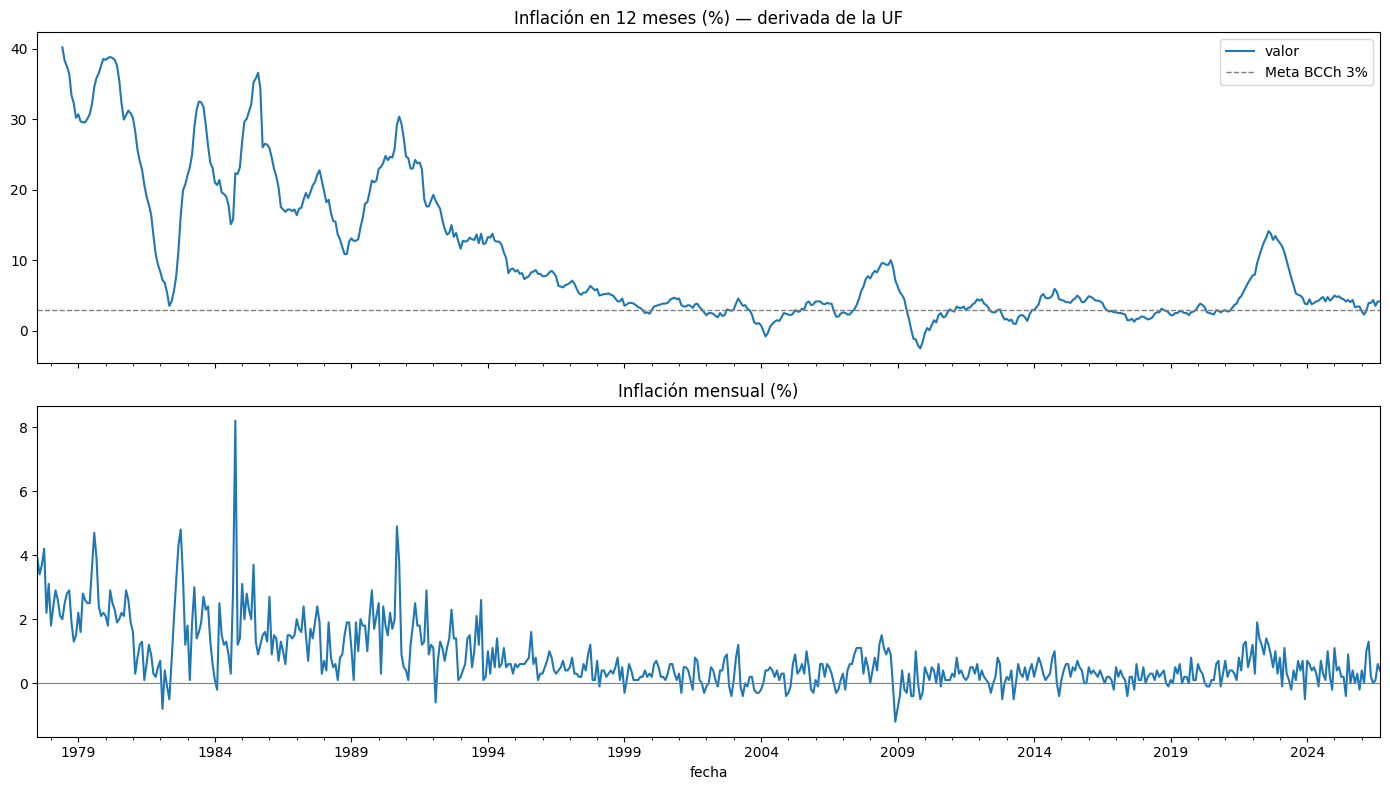

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

inflacion_12m.plot(ax=ejes[0])
ejes[0].set_title("Inflación en 12 meses (%) — derivada de la UF")
ejes[0].axhline(3, color="gray", linestyle="--", linewidth=1, label="Meta BCCh 3%")
ejes[0].legend()

inflacion_mensual.plot(ax=ejes[1])
ejes[1].set_title("Inflación mensual (%)")
ejes[1].axhline(0, color="gray", linewidth=0.8)

plt.tight_layout()
plt.show()

In [7]:
# Estimar el AR(1)

from statsmodels.tsa.ar_model import AutoReg

muestra = inflacion_mensual["2001-01":]

modelo = AutoReg(muestra.to_numpy(), lags=1, trend="c").fit()
print(modelo.summary())

a, b = modelo.params
sigma = np.std(modelo.resid, ddof=2)
media_mensual = a / (1 - b)
media_anual = ((1 + media_mensual / 100) ** 12 - 1) * 100

print(f"\na (nivel)          = {a:.4f}")
print(f"b (persistencia)   = {b:.4f}")
print(f"sigma (shock)      = {sigma:.4f} puntos porcentuales por mes")
print(f"Media de largo plazo: {media_mensual:.3f}% mensual ≈ {media_anual:.2f}% anual")
if 0 < b < 1:
    print(f"Vida media de un shock: {np.log(0.5) / np.log(b):.1f} meses")

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  308
Model:                     AutoReg(1)   Log Likelihood                -146.941
Method:               Conditional MLE   S.D. of innovations              0.390
Date:                Tue, 20 Oct 2026   AIC                            299.882
Time:                        15:47:31   BIC                            311.073
Sample:                             1   HQIC                           304.357
                                  309                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1942      0.028      7.025      0.000       0.140       0.248
y.L1           0.3785      0.053      7.176      0.000       0.275       0.482
                                    Roots           

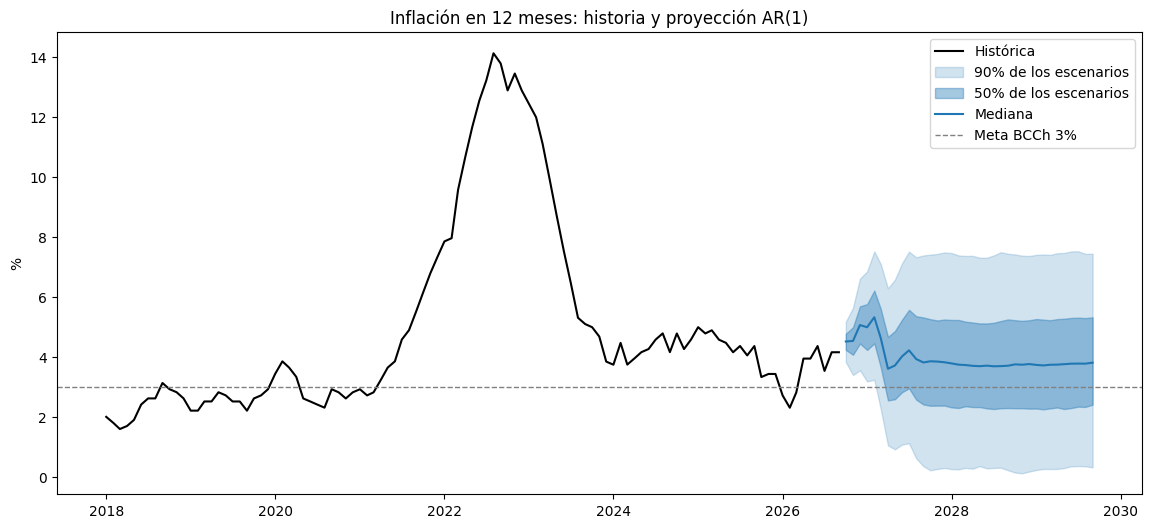

En 12 meses: mediana 3.83% | rango 90%: 0.37% a 7.39% | P(inflación > 5%) = 29.7%
En 24 meses: mediana 3.72% | rango 90%: 0.23% a 7.45% | P(inflación > 5%) = 29.2%
En 36 meses: mediana 3.82% | rango 90%: 0.33% a 7.45% | P(inflación > 5%) = 29.8%


In [8]:
# Simulación de 5000 iteraciones durante 3 años.

rng = np.random.default_rng(42)   # semilla fija: mismo resultado cada vez
N, H = 5000, 36                   # trayectorias y meses a simular

# Simular la inflación mensual: x(t+1) = a + b·x(t) + sigma·shock
x = np.full(N, muestra.iloc[-1])
mensual_sim = np.empty((N, H))
for t in range(H):
    x = a + b * x + sigma * rng.standard_normal(N)
    mensual_sim[:, t] = x

# Pasar a inflación en 12 meses: cada mes simulado se acumula con los 11 anteriores
ultimos_11 = muestra.iloc[-11:].to_numpy()
completo = np.hstack([np.tile(ultimos_11, (N, 1)), mensual_sim])
factores = 1 + completo / 100
infl_12m_sim = np.column_stack([
    (np.prod(factores[:, t:t + 12], axis=1) - 1) * 100 for t in range(H)
])

fechas_futuras = pd.period_range(muestra.index[-1] + 1, periods=H, freq="M")
p5, p25, p50, p75, p95 = np.percentile(infl_12m_sim, [5, 25, 50, 75, 95], axis=0)

# Gráfico: historia desde 2018 + abanico
fig, ax = plt.subplots(figsize=(14, 6))
historia = inflacion_12m["2018-01":]
ax.plot(historia.index.to_timestamp(), historia.values, color="black", label="Histórica")

x_fut = fechas_futuras.to_timestamp()
ax.fill_between(x_fut, p5, p95, alpha=0.2, color="tab:blue", label="90% de los escenarios")
ax.fill_between(x_fut, p25, p75, alpha=0.4, color="tab:blue", label="50% de los escenarios")
ax.plot(x_fut, p50, color="tab:blue", label="Mediana")
ax.axhline(3, color="gray", linestyle="--", linewidth=1, label="Meta BCCh 3%")
ax.set_title("Inflación en 12 meses: historia y proyección AR(1)")
ax.set_ylabel("%")
ax.legend()
plt.show()

for meses in (12, 24, 36):
    prob = (infl_12m_sim[:, meses - 1] > 5).mean() * 100
    print(f"En {meses} meses: mediana {p50[meses - 1]:.2f}% | "
          f"rango 90%: {p5[meses - 1]:.2f}% a {p95[meses - 1]:.2f}% | "
          f"P(inflación > 5%) = {prob:.1f}%")

In [9]:
# Comprobando el modelo con datos reales del dataset.

historia_meta = inflacion_12m["2001-01":]
print(f"Meses con inflación en 12 meses > 5% desde 2001: {(historia_meta > 5).mean() * 100:.1f}%")
print(f"Rango 5%-95% histórico: {historia_meta.quantile(0.05):.2f}% a {historia_meta.quantile(0.95):.2f}%")

Meses con inflación en 12 meses > 5% desde 2001: 16.5%
Rango 5%-95% histórico: 0.99% a 9.58%


In [10]:
# Ahora vamos a generar 2 otros modelos para comparar cual es mejor, lo de abajo son funciones auxiliares.

def a_12_meses(mensual_sim, ultimos_11):
    """Convierte trayectorias de inflación mensual (N x H) en inflación de 12 meses,
    acumulando cada mes con los 11 anteriores (los primeros vienen de la historia real)."""
    N, H = mensual_sim.shape
    completo = np.hstack([np.tile(ultimos_11, (N, 1)), mensual_sim])
    factores = 1 + completo / 100
    return np.column_stack([
        (np.prod(factores[:, t:t + 12], axis=1) - 1) * 100 for t in range(H)
    ])


def duraciones_sobre(fila_bool):
    """Largo de cada racha consecutiva de True (ej. meses seguidos con inflación > 5%)."""
    duraciones, cont = [], 0
    for v in fila_bool:
        if v:
            cont += 1
        elif cont:
            duraciones.append(cont)
            cont = 0
    if cont:
        duraciones.append(cont)
    return duraciones


def evaluar(nombre, infl_12m, descartar=12, umbral=5):
    """Métricas para comparar con la historia. Descarta los primeros meses (efecto base)."""
    datos = infl_12m[:, descartar:]
    rachas = [d for fila in datos for d in duraciones_sobre(fila > umbral)]
    return {
        "modelo": nombre,
        f"% meses > {umbral}%": round((datos > umbral).mean() * 100, 1),
        "p5": round(np.percentile(datos, 5), 2),
        "p95": round(np.percentile(datos, 95), 2),
        f"duración media sobre {umbral}% (meses)": round(np.mean(rachas), 1) if rachas else 0,
        f"duración máxima sobre {umbral}% (meses)": max(rachas) if rachas else 0,
    }


def simular_ar1(a, b, sigma, x0, N, H, rng):
    x = np.full(N, x0)
    sim = np.empty((N, H))
    for t in range(H):
        x = a + b * x + sigma * rng.standard_normal(N)
        sim[:, t] = x
    return sim


N, H = 5000, 120
ultimos_11 = muestra.iloc[-11:].to_numpy()

In [11]:
# Usamos de referencia el modelo AR(1), la idea es usar esto para comparar los periodos de más de 5% y su duración.

rng = np.random.default_rng(42)
ar1_12m = a_12_meses(simular_ar1(a, b, sigma, muestra.iloc[-1], N, H, rng), ultimos_11)

historia_meta = inflacion_12m["2001-01":].to_numpy()
rachas_hist = duraciones_sobre(historia_meta > 5)
fila_historia = {
    "modelo": "HISTORIA 2001-2026",
    "% meses > 5%": round((historia_meta > 5).mean() * 100, 1),
    "p5": round(np.percentile(historia_meta, 5), 2),
    "p95": round(np.percentile(historia_meta, 95), 2),
    "duración media sobre 5% (meses)": round(np.mean(rachas_hist), 1),
    "duración máxima sobre 5% (meses)": max(rachas_hist),
}
print("Episodios sobre 5% en la historia (duración en meses):", rachas_hist)

Episodios sobre 5% en la historia (duración en meses): [19, 1, 3, 1, 26, 1]


In [12]:
# Ahora generamos el segundo modelo: bootstrap por bloques, esto corta y pega en el futuro lo ocurrido antes.

def bootstrap_bloques(serie, N, H, largo, rng):
    """Futuros armados con bloques consecutivos de la historia real, elegidos al azar."""
    valores = serie.to_numpy()
    n_bloques = int(np.ceil(H / largo))
    inicios = rng.integers(0, len(valores) - largo + 1, size=(N, n_bloques))
    indices = inicios[:, :, None] + np.arange(largo)   # N x bloques x largo
    return valores[indices].reshape(N, -1)[:, :H]


rng = np.random.default_rng(42)
boot12_12m = a_12_meses(bootstrap_bloques(muestra, N, H, 12, rng), ultimos_11)
boot24_12m = a_12_meses(bootstrap_bloques(muestra, N, H, 24, rng), ultimos_11)

In [13]:
# La comparación del AR(1) con bootstrap por bloques.

comparacion = pd.DataFrame([
    fila_historia,
    evaluar("AR(1)", ar1_12m),
    evaluar("Bootstrap bloques 12 meses", boot12_12m),
    evaluar("Bootstrap bloques 24 meses", boot24_12m),
]).set_index("modelo")

comparacion

,% meses > 5%,p5,p95,duración media sobre 5% (meses),duración máxima sobre 5% (meses)
modelo,,,,,
HISTORIA 2001-2026,16.5,0.99,9.58,8.5,26
AR(1),29.1,0.28,7.45,7.0,65
Bootstrap bloques 12 meses,21.0,0.79,8.82,7.3,56
Bootstrap bloques 24 meses,19.6,0.79,9.37,7.6,89


                         Markov Switching Model Results                         
Dep. Variable:                        y   No. Observations:                  308
Model:             MarkovAutoregression   Log Likelihood                -131.737
Date:                  Tue, 20 Oct 2026   AIC                            277.475
Time:                          16:03:02   BIC                            303.586
Sample:                               0   HQIC                           287.915
                                  - 308                                         
Covariance Type:                 approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2389      0.032      7.562      0.000       0.177       0.301
sigma2         0.0874      0.012    

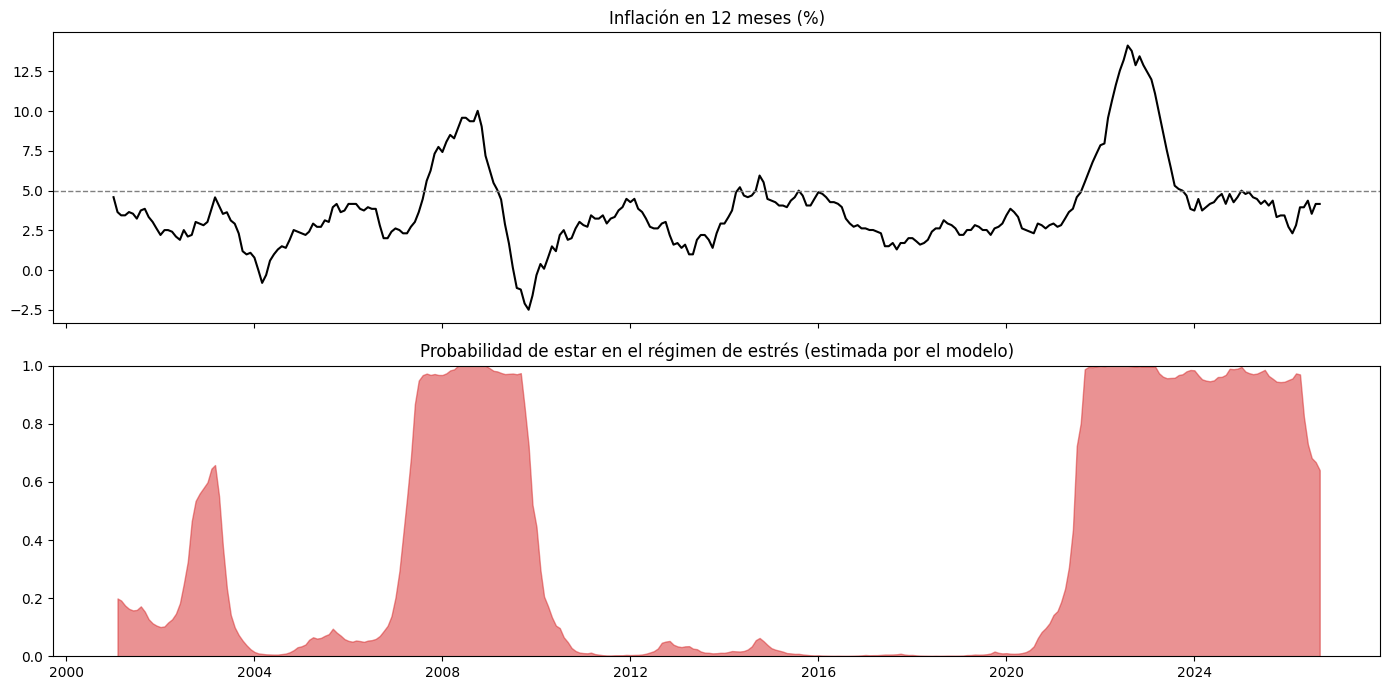

In [16]:
# Ahora ocupamos markov para ver si el modelo encuentra y diferencia los periodos inflacionarios de los no inflacionarios.

from statsmodels.tsa.regime_switching.markov_autoregression import MarkovAutoregression

modelo_mk = MarkovAutoregression(
    muestra.to_numpy(),
    k_regimes=2,
    order=1,
    switching_ar=False,        # misma persistencia en ambos regímenes (más simple, se puede liberar después)
    switching_variance=True,   # cada régimen con su propia volatilidad
)
# search_reps: prueba varios puntos de partida para no quedarse en un óptimo local
res_mk = modelo_mk.fit(search_reps=20)
print(res_mk.summary())

# Con entrada numpy, params viene sin nombres: se los ponemos para leerlos por nombre
params_mk = pd.Series(res_mk.params, index=res_mk.model.param_names)
print(params_mk.round(4))

# Identificar cuál régimen es el de estrés: el de media más alta
medias = params_mk[["const[0]", "const[1]"]].to_numpy()
estres = int(np.argmax(medias))
normal = 1 - estres

prob_estres = pd.Series(
    res_mk.smoothed_marginal_probabilities[:, estres],
    index=muestra.index[1:].to_timestamp(),
)

# Gráfico: los dos paneles con fechas normales (timestamp) para que compartan bien el eje X
infl_meta = inflacion_12m["2001-01":]

fig, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ejes[0].plot(infl_meta.index.to_timestamp(), infl_meta.values, color="black")
ejes[0].axhline(5, color="gray", linestyle="--", linewidth=1)
ejes[0].set_title("Inflación en 12 meses (%)")
ejes[1].fill_between(prob_estres.index, prob_estres.values, color="tab:red", alpha=0.5)
ejes[1].set_ylim(0, 1)
ejes[1].set_title("Probabilidad de estar en el régimen de estrés (estimada por el modelo)")
plt.tight_layout()
plt.show()

In [17]:
# El modelo de markov clasifica relativamente bien, con lo aprendido lo ocupamos para proyectar.

phi = params_mk["ar.L1"]
mu = np.array([params_mk["const[0]"], params_mk["const[1]"]])
sd = np.sqrt([params_mk["sigma2[0]"], params_mk["sigma2[1]"]])
p00, p10 = params_mk["p[0->0]"], params_mk["p[1->0]"]
P = np.array([[p00, 1 - p00],    # desde el régimen 0: quedarse / pasar al 1
              [p10, 1 - p10]])   # desde el régimen 1: pasar al 0 / quedarse

# Probabilidad de estar en el régimen 1 en el último mes observado: punto de partida de cada escenario
prob_inicial_r1 = res_mk.smoothed_marginal_probabilities[-1, 1]


def simular_markov(mu, sd, phi, P, x0, prob_inicial_r1, N, H, rng):
    s_prev = (rng.random(N) < prob_inicial_r1).astype(int)
    x_prev = np.full(N, x0)
    sim = np.empty((N, H))
    estados = np.empty((N, H), dtype=int)
    for t in range(H):
        s = np.where(rng.random(N) < P[s_prev, 0], 0, 1)    # sorteo del régimen de este mes
        x = mu[s] + phi * (x_prev - mu[s_prev]) + sd[s] * rng.standard_normal(N)
        sim[:, t] = x
        estados[:, t] = s
        s_prev, x_prev = s, x
    return sim, estados


print(f"Punto de partida: {prob_inicial_r1 * 100:.0f}% de los escenarios en el régimen 1")
print(f"Régimen de estrés = régimen {estres}")

Punto de partida: 64% de los escenarios en el régimen 1
Régimen de estrés = régimen 1


In [18]:
# Comparación de los modelos en un periodo de 25 años.

N, H = 5000, 300   # 25 años por escenario, igual que la historia
x0 = muestra.iloc[-1]


def evaluar(nombre, infl_12m, descartar=12, umbral=5):
    datos = infl_12m[:, descartar:]
    rachas_por_fila = [duraciones_sobre(fila > umbral) for fila in datos]
    rachas = [d for r in rachas_por_fila for d in r]
    maximos = [max(r) if r else 0 for r in rachas_por_fila]
    return {
        "modelo": nombre,
        f"% meses > {umbral}%": round((datos > umbral).mean() * 100, 1),
        "p5": round(np.percentile(datos, 5), 2),
        "p95": round(np.percentile(datos, 95), 2),
        "duración media episodio (meses)": round(np.mean(rachas), 1) if rachas else 0,
        "episodio más largo en 25 años (mediana)": float(np.median(maximos)),
    }


rng = np.random.default_rng(42)
ar1_12m = a_12_meses(simular_ar1(a, b, sigma, x0, N, H, rng), ultimos_11)
boot24_12m = a_12_meses(bootstrap_bloques(muestra, N, H, 24, rng), ultimos_11)
mk_mensual, mk_estados = simular_markov(mu, sd, phi, P, x0, prob_inicial_r1, N, H, rng)
mk_12m = a_12_meses(mk_mensual, ultimos_11)

fila_historia = {
    "modelo": "HISTORIA 2001-2026",
    "% meses > 5%": round((historia_meta > 5).mean() * 100, 1),
    "p5": round(np.percentile(historia_meta, 5), 2),
    "p95": round(np.percentile(historia_meta, 95), 2),
    "duración media episodio (meses)": round(np.mean(rachas_hist), 1),
    "episodio más largo en 25 años (mediana)": float(max(rachas_hist)),
}

comparacion = pd.DataFrame([
    fila_historia,
    evaluar("AR(1)", ar1_12m),
    evaluar("Bootstrap bloques 24 meses", boot24_12m),
    evaluar("Markov 2 regímenes", mk_12m),
]).set_index("modelo")

print(f"Markov: % del tiempo simulado en estrés = {(mk_estados == estres).mean() * 100:.1f}%")
comparacion

Markov: % del tiempo simulado en estrés = 37.3%


,% meses > 5%,p5,p95,duración media episodio (meses),episodio más largo en 25 años (mediana)
modelo,,,,,
HISTORIA 2001-2026,16.5,0.99,9.58,8.5,26.0
AR(1),29.3,0.29,7.43,7.3,20.0
Bootstrap bloques 24 meses,19.8,0.79,9.37,7.9,22.0
Markov 2 regímenes,27.0,0.69,8.28,8.3,23.0


**La comparación mostró que markov tiene falencias a trabajar y que no podemos testear bootstrap con los mismos datos con los que fue entrenado ya que samplea los mismos datos. Por ahora vamos a probar entrenar y testear los modelos con segmentos distintos de los datos para juzgar mejor como modelan la información.**

In [20]:
# Generamos las métricas y las ventanas.
""" 
Cómo leer cada métrica:

Cobertura 90%: en qué porcentaje de los meses de prueba la realidad cayó dentro del rango del 90% del modelo. Lo ideal es cerca de 90. 
Mucho menos significa que el modelo es demasiado confiado; 100 con un abanico enorme significa que es demasiado vago.

Cobertura 50%: lo mismo para el rango central. Lo ideal es cerca de 50.

P(>5%) asignada vs % real > 5%: cuánta probabilidad le dio el modelo a la inflación alta, comparada con lo que ocurrió.

p95 más alto simulado vs máximo real: si el modelo siquiera contemplaba valores como los que ocurrieron.

CRPS: un puntaje que resume todo. Premia los abanicos angostos que igual contienen la realidad. 
Es la métrica para comparar modelos entre sí: menor es mejor.
"""




def crps_ensemble(muestras, observado):
    """CRPS: castiga tanto errar el centro como dar un abanico innecesariamente ancho.
    Menor es mejor. Fórmula exacta para un conjunto de escenarios."""
    x = np.sort(muestras)
    n = len(x)
    i = np.arange(1, n + 1)
    return np.mean(np.abs(x - observado)) - np.sum((2 * i - n - 1) * x) / n**2


def evaluar_ventana(sim_12m, reales):
    """Compara el abanico simulado (N x H) con la inflación real de cada mes de la prueba (H)."""
    p5, p25, p75, p95 = np.percentile(sim_12m, [5, 25, 75, 95], axis=0)
    return {
        "cobertura 90% (ideal 90)": round(((reales >= p5) & (reales <= p95)).mean() * 100, 1),
        "cobertura 50% (ideal 50)": round(((reales >= p25) & (reales <= p75)).mean() * 100, 1),
        "P(>5%) asignada": round((sim_12m > 5).mean() * 100, 1),
        "% real > 5%": round((reales > 5).mean() * 100, 1),
        "p95 más alto simulado": round(p95.max(), 2),
        "máximo real": round(reales.max(), 2),
        "CRPS (menor es mejor)": round(
            np.mean([crps_ensemble(sim_12m[:, t], reales[t]) for t in range(len(reales))]), 3
        ),
    }


# (nombre, último mes de entrenamiento, último mes de prueba; None = hasta el final)
VENTANAS = [
    ("2001-2012 → 2013-2016", "2012-12", "2016-12"),
    ("2001-2016 → 2017-2020", "2016-12", "2020-12"),
    ("2001-2020 → 2021-2026", "2020-12", None),
]

In [21]:
# Formateamos los modelos para que reciban los datos de la misma forma y retornen una función.

def modelo_ar1(train):
    res = AutoReg(train.to_numpy(), lags=1, trend="c").fit()
    a_, b_ = res.params
    s_ = np.std(res.resid, ddof=2)
    x0_ = train.iloc[-1]
    return lambda N, H, rng: simular_ar1(a_, b_, s_, x0_, N, H, rng)


def modelo_bootstrap(train, largo=24):
    return lambda N, H, rng: bootstrap_bloques(train, N, H, largo, rng)


def ajustar_markov(train):
    mod = MarkovAutoregression(
        train.to_numpy(), k_regimes=2, order=1,
        switching_ar=False, switching_variance=True,
    )
    res = mod.fit(search_reps=10)
    params = pd.Series(res.params, index=res.model.param_names)
    P_ = np.array([
        [params["p[0->0]"], 1 - params["p[0->0]"]],
        [params["p[1->0]"], 1 - params["p[1->0]"]],
    ])
    return res, params, P_


def modelo_markov(train):
    res, p, P_ = ajustar_markov(train)
    mu_ = np.array([p["const[0]"], p["const[1]"]])
    sd_ = np.sqrt([p["sigma2[0]"], p["sigma2[1]"]])
    prob1 = res.smoothed_marginal_probabilities[-1, 1]
    x0_ = train.iloc[-1]
    return lambda N, H, rng: simular_markov(mu_, sd_, p["ar.L1"], P_, x0_, prob1, N, H, rng)[0]


def tramos_contiguos(posiciones):
    """Agrupa posiciones consecutivas: [3,4,5,9,10] -> [[3,5],[9,10]] (inicio y fin incluidos)."""
    tramos = []
    for i in posiciones:
        if tramos and i == tramos[-1][1] + 1:
            tramos[-1][1] = i
        else:
            tramos.append([i, i])
    return tramos


def modelo_hibrido(train):
    """El Markov clasifica los meses y genera la secuencia de regímenes;
    los valores salen de tramos reales consecutivos del mismo régimen."""
    res, _, P_ = ajustar_markov(train)
    prob1_hist = res.smoothed_marginal_probabilities[:, 1]   # alineado con train[1:]
    valores = train.to_numpy()[1:]
    etiquetas = (prob1_hist > 0.5).astype(int)
    bancos = {r: tramos_contiguos(np.where(etiquetas == r)[0]) for r in (0, 1)}
    prob1_ini = prob1_hist[-1]

    def simular(N, H, rng):
        sim = np.empty((N, H))
        for n in range(N):
            s = int(rng.random() < prob1_ini)
            pos, fin = None, -1
            for t in range(H):
                s_nuevo = 0 if rng.random() < P_[s, 0] else 1
                # Nuevo tramo si cambió el régimen o se acabó el tramo actual
                if s_nuevo != s or pos is None or pos > fin:
                    s = s_nuevo
                    tramos = bancos[s] or bancos[1 - s]   # por si un banco quedara vacío
                    largos = np.array([f - i + 1 for i, f in tramos])
                    k = rng.choice(len(tramos), p=largos / largos.sum())
                    inicio, fin = tramos[k]
                    pos = rng.integers(inicio, fin + 1)
                sim[n, t] = valores[pos]
                pos += 1
        return sim

    return simular


MODELOS = {
    "AR(1)": modelo_ar1,
    "Bootstrap 24": modelo_bootstrap,
    "Markov": modelo_markov,
    "Híbrido": modelo_hibrido,
}

In [ ]:
# Corremos el backtesting, el entrenamiento.

N_BT = 2000
resultados = []
abanicos = {}   # se guardan para graficar en la celda siguiente

for nombre_v, fin_train, fin_test in VENTANAS:
    corte = pd.Period(fin_train, "M")
    train = muestra[muestra.index <= corte]
    reales = inflacion_12m[inflacion_12m.index > corte]
    if fin_test:
        reales = reales[reales.index <= pd.Period(fin_test, "M")]

    ultimos_11_v = train.iloc[-11:].to_numpy()
    for nombre_m, construir in MODELOS.items():
        rng = np.random.default_rng(42)
        simular = construir(train)
        sim_12m = a_12_meses(simular(N_BT, len(reales), rng), ultimos_11_v)
        resultados.append({
            "ventana": nombre_v,
            "modelo": nombre_m,
            **evaluar_ventana(sim_12m, reales.to_numpy()),
        })
        abanicos[(nombre_v, nombre_m)] = (reales, sim_12m)

tabla_bt = pd.DataFrame(resultados).set_index(["ventana", "modelo"])
tabla_bt

cobertura 90% (ideal 90)  \
ventana               modelo                                   
2001-2012 → 2013-2016 AR(1)                            100.0   
                      Bootstrap 24                     100.0   
                      Markov                           100.0   
                      Híbrido                          100.0   
2001-2016 → 2017-2020 AR(1)                            100.0   
                      Bootstrap 24                     100.0   
                      Markov                           100.0   
                      Híbrido                          100.0   
2001-2020 → 2021-2026 AR(1)                             68.1   
                      Bootstrap 24                      73.9   
                      Markov                            68.1   
                      Híbrido                           66.7   

                                    cobertura 50% (ideal 50)  P(>5%) asignada  \
ventana               modelo                                                    
2001-2012 → 2013-2016 AR(1)                             83.3             18.3   
                      Bootstrap 24                      47.9             14.3   
                      Markov                            83.3             19.3   
                      Híbrido                           39.6             10.6   
2001-2016 → 2017-2020 AR(1)                             89.6             17.1   
                      Bootstrap 24                      85.4             13.3   
                      Markov                            87.5             14.8   
                      Híbrido                           81.2              9.9   
2001-2020 → 2021-2026 AR(1)                             42.0             16.1   
                      Bootstrap 24                      23.2             10.9   
                      Markov                            30.4             12.5   
                      Híbrido                           20.3              8.8   

                                    % real > 5%  p95 más alto simulado  \
ventana               modelo                                             
2001-2012 → 2013-2016 AR(1)                10.4                   7.52   
                      Bootstrap 24         10.4                   9.04   
                      Markov               10.4                   7.87   
                      Híbrido              10.4                   7.55   
2001-2016 → 2017-2020 AR(1)                 0.0                   7.21   
                      Bootstrap 24          0.0                   8.94   
                      Markov                0.0                   7.32   
                      Híbrido               0.0                   6.78   
2001-2020 → 2021-2026 AR(1)                39.1                   6.68   
                      Bootstrap 24         39.1                   8.29   
                      Markov               39.1                   6.71   
                      Híbrido              39.1                   6.47   

                                    máximo real  CRPS (menor es mejor)  
ventana               modelo                                            
2001-2012 → 2013-2016 AR(1)                5.95                  0.770  
                      Bootstrap 24         5.95                  0.785  
                      Markov               5.95                  0.777  
                      Híbrido              5.95                  1.011  
2001-2016 → 2017-2020 AR(1)                3.86                  0.584  
                      Bootstrap 24         3.86                  0.514  
                      Markov               3.86                  0.534  
                      Híbrido              3.86                  0.489  
2001-2020 → 2021-2026 AR(1)               14.13                  2.480  
                      Bootstrap 24        14.13                  2.525  
                      Markov              14.13                  2.541  
                  

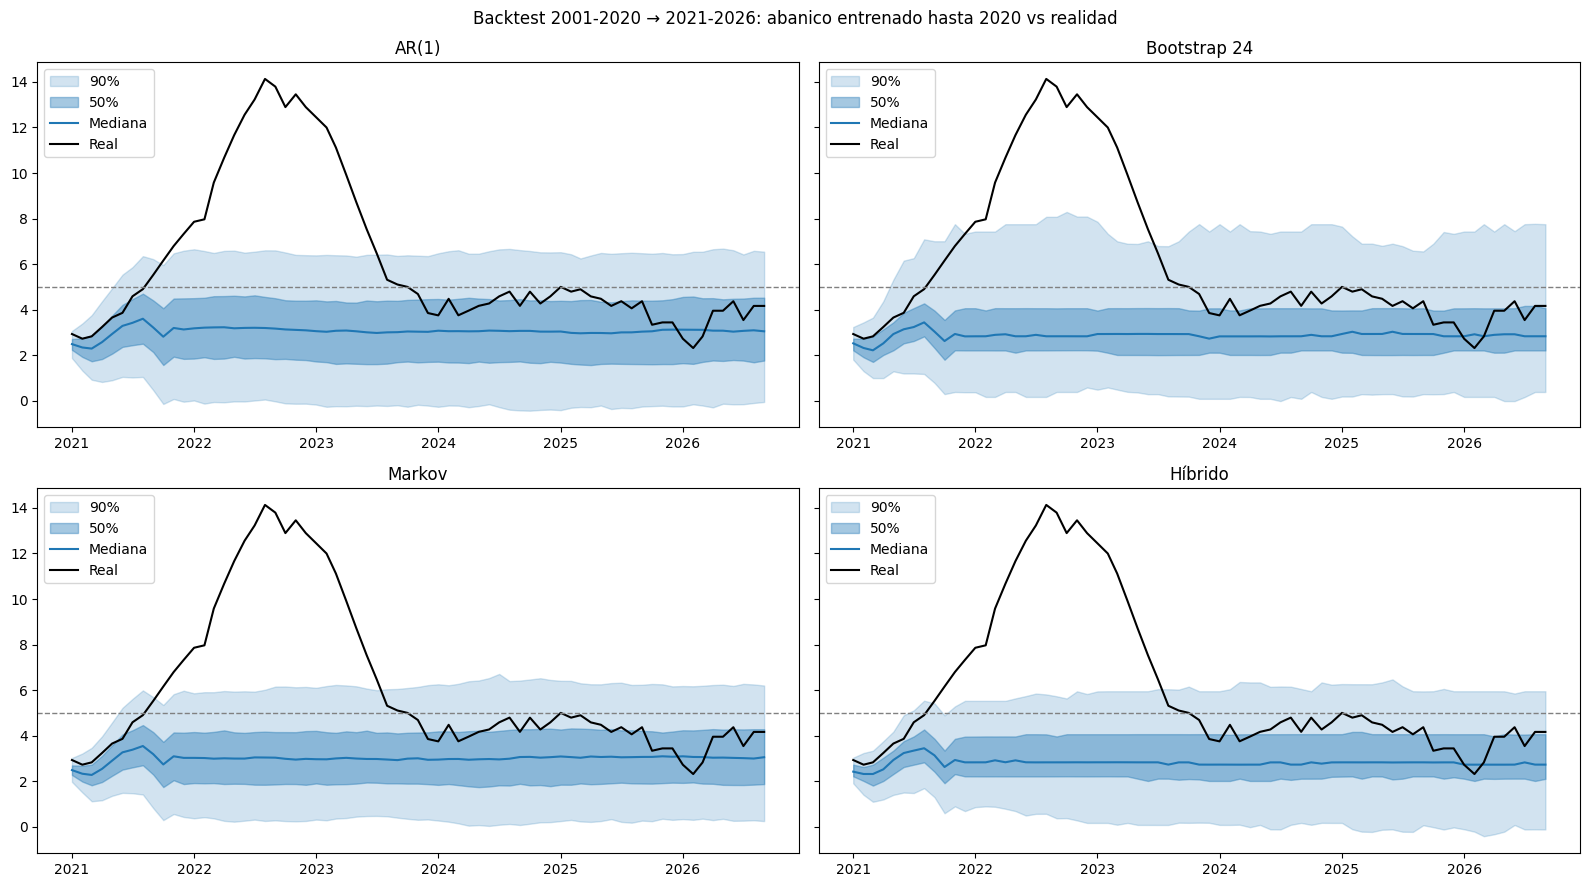

In [23]:
# Probamos los modelos entrenados con el dataset de verificación.

nombre_v = VENTANAS[-1][0]
fig, ejes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

for ax, nombre_m in zip(ejes.flat, MODELOS):
    reales, sim = abanicos[(nombre_v, nombre_m)]
    x = reales.index.to_timestamp()
    p5, p25, p50, p75, p95 = np.percentile(sim, [5, 25, 50, 75, 95], axis=0)
    ax.fill_between(x, p5, p95, alpha=0.2, color="tab:blue", label="90%")
    ax.fill_between(x, p25, p75, alpha=0.4, color="tab:blue", label="50%")
    ax.plot(x, p50, color="tab:blue", label="Mediana")
    ax.plot(x, reales.values, color="black", label="Real")
    ax.axhline(5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(nombre_m)
    ax.legend(loc="upper left")

fig.suptitle(f"Backtest {nombre_v}: abanico entrenado hasta 2020 vs realidad")
plt.tight_layout()
plt.show()

**El resultado sigue siendo malo para lo que necesitamos, dejamos esto hasta acá por ahora.**